
# Deep Learning Lab 05 — Optimization Algorithms
**Google Colab notebook — complete solution for Tasks 1–6**

This notebook follows the lab manual requirements:
- Architecture: **[2, 32, 16, 1]**
- Hidden activations: **ReLU**
- Output activation: **Sigmoid**
- Initialization: **He initialization**
- Dataset: generated two-arm spiral
- Core libraries: **NumPy + Matplotlib only**
- Optimizers: GD, Momentum, RMSProp, Adam
- Default batch size: 64 unless a task says otherwise

> Change `YOUR_ROLL_NO` below before submission.  
> Then save the notebook as `Lab05_<YourRollNo>.ipynb`.


In [1]:

YOUR_ROLL_NO = "60"

import numpy as np
import matplotlib.pyplot as plt
import time
import math

np.set_printoptions(precision=6, suppress=True)

def print_table(headers, rows):
    rows = [[str(x) for x in row] for row in rows]
    widths = [len(str(h)) for h in headers]
    for row in rows:
        for i, x in enumerate(row):
            widths[i] = max(widths[i], len(x))
    fmt = " | ".join("{:<" + str(w) + "}" for w in widths)
    print(fmt.format(*headers))
    print("-+-".join("-"*w for w in widths))
    for row in rows:
        print(fmt.format(*row))


## Dataset + reusable neural-network code

X_train: (2, 2400) Y_train: (1, 2400)
X_test : (2, 600) Y_test : (1, 600)


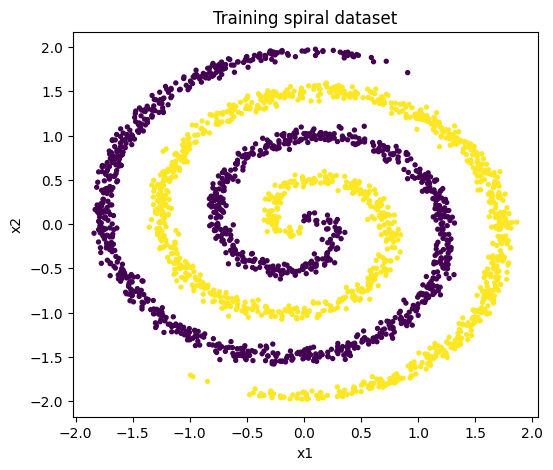

In [2]:

def make_spiral(n_per=1500, noise=0.30, seed=5, turns=4.0):
    rng = np.random.RandomState(seed)
    Xs, ys = [], []
    for c in (0, 1):
        t = np.sqrt(rng.rand(n_per)) * turns * np.pi
        th = t + c*np.pi + rng.randn(n_per)*noise
        Xs.append(np.c_[t*np.sin(th), t*np.cos(th)])
        ys.append(np.full(n_per, c))
    Xa = np.vstack(Xs)
    ya = np.concatenate(ys)
    p = rng.permutation(len(ya))
    return Xa[p], ya[p]

Xa, ya = make_spiral()
Xa = (Xa - Xa.mean(0)) / Xa.std(0)

X_train = Xa[:2400].T
Y_train = ya[:2400].reshape(1, -1)
X_test  = Xa[2400:].T
Y_test  = ya[2400:].reshape(1, -1)

print("X_train:", X_train.shape, "Y_train:", Y_train.shape)
print("X_test :", X_test.shape,  "Y_test :", Y_test.shape)

plt.figure(figsize=(6,5))
plt.scatter(X_train[0], X_train[1], c=Y_train.ravel(), s=8)
plt.title("Training spiral dataset")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()


In [3]:

# ---------- Neural network ----------
LAYER_DIMS = [2, 32, 16, 1]

def initialize_parameters(seed=1, dims=LAYER_DIMS):
    rng = np.random.RandomState(seed)
    P = {}
    for l in range(1, len(dims)):
        P[f"W{l}"] = rng.randn(dims[l], dims[l-1]) * np.sqrt(2.0 / dims[l-1])
        P[f"b{l}"] = np.zeros((dims[l], 1))
    return P

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -40, 40)))

def forward_propagation(X, P):
    A = X
    caches = []
    L = len(P)//2
    for l in range(1, L):
        Z = P[f"W{l}"] @ A + P[f"b{l}"]
        caches.append((A, Z))
        A = np.maximum(0, Z)
    ZL = P[f"W{L}"] @ A + P[f"b{L}"]
    AL = sigmoid(ZL)
    caches.append((A, ZL))
    return AL, caches

def compute_cost(AL, Y):
    eps = 1e-12
    return -np.mean(Y*np.log(AL + eps) + (1-Y)*np.log(1-AL + eps))

def backward_propagation(AL, Y, P, caches):
    grads = {}
    m = Y.shape[1]
    L = len(P)//2
    dZ = AL - Y

    for l in range(L, 0, -1):
        A_prev, Z = caches[l-1]
        grads[f"dW{l}"] = (dZ @ A_prev.T) / m
        grads[f"db{l}"] = np.sum(dZ, axis=1, keepdims=True) / m

        if l > 1:
            dA_prev = P[f"W{l}"].T @ dZ
            Z_prev = caches[l-2][1]
            dZ = dA_prev * (Z_prev > 0)
    return grads

def accuracy(X, Y, P):
    AL, _ = forward_propagation(X, P)
    pred = (AL >= 0.5).astype(int)
    return np.mean(pred == Y)

def zeros_like_grads(P):
    state = {}
    for l in range(1, len(P)//2 + 1):
        state[f"dW{l}"] = np.zeros_like(P[f"W{l}"])
        state[f"db{l}"] = np.zeros_like(P[f"b{l}"])
    return state



# Task 1 — Mini-Batch Machinery and Batch Size

The manual asks us to verify batch sizes 512 and 700 and says 512 divides 2400 exactly.  
**Important:** mathematically, `2400 % 512 = 352`, so 512 does **not** divide 2400 exactly.  
To preserve the manual's requested checks, this notebook prints 512 and 700, and also prints 600 as a truly exact-divisor example.


In [4]:

def random_mini_batches(X, Y, batch_size=64, seed=0):
    rng = np.random.RandomState(seed)
    m = X.shape[1]

    perm = rng.permutation(m)
    Xs = X[:, perm]
    Ys = Y[:, perm].reshape((1, m))

    batches = []
    n_full = m // batch_size

    for k in range(n_full):
        start = k * batch_size
        end = (k + 1) * batch_size
        batches.append((Xs[:, start:end], Ys[:, start:end]))

    if m % batch_size != 0:
        start = n_full * batch_size
        batches.append((Xs[:, start:], Ys[:, start:]))

    return batches

for bs in [512, 700, 600]:
    b = random_mini_batches(X_train, Y_train, batch_size=bs, seed=0)
    print(f"batch_size={bs:>3} -> number of batches={len(b)}, sizes={[x.shape[1] for x,_ in b]}")

print("\nWhy shuffle first?")
print("So each batch is a representative mixture of training examples instead of preserving any ordering bias.")
print("Why vary seed each epoch?")
print("So the batch composition changes from epoch to epoch while remaining reproducible.")


batch_size=512 -> number of batches=5, sizes=[512, 512, 512, 512, 352]
batch_size=700 -> number of batches=4, sizes=[700, 700, 700, 300]
batch_size=600 -> number of batches=4, sizes=[600, 600, 600, 600]

Why shuffle first?
So each batch is a representative mixture of training examples instead of preserving any ordering bias.
Why vary seed each epoch?
So the batch composition changes from epoch to epoch while remaining reproducible.


In [5]:

# ---------- General training function used for Tasks 1, 3, 4 and 5 ----------
def train_model(
    optimizer="gd",
    lr=0.1,
    epochs=100,
    batch_size=64,
    seed=1,
    beta1=0.9,
    beta2=0.999,
    epsilon=1e-8,
    schedule=None,
    reset_adam_t_each_epoch=False,
    rmsprop_bias_correction=False,
    record_batch_cost=False
):
    P = initialize_parameters(seed=seed)
    v = zeros_like_grads(P)
    s = zeros_like_grads(P)

    epoch_costs = []
    batch_costs = []
    lr_history = []
    t = 0
    updates = 0

    start_time = time.perf_counter()

    for epoch in range(epochs):
        current_lr = lr if schedule is None else schedule(lr, epoch)
        lr_history.append(current_lr)

        if reset_adam_t_each_epoch:
            t = 0

        mini_batches = random_mini_batches(
            X_train, Y_train, batch_size=batch_size, seed=seed + epoch
        )

        for Xb, Yb in mini_batches:
            AL, caches = forward_propagation(Xb, P)
            if record_batch_cost:
                batch_costs.append(compute_cost(AL, Yb))
            grads = backward_propagation(AL, Yb, P, caches)

            t += 1
            updates += 1

            for l in range(1, len(P)//2 + 1):
                for p in ("W", "b"):
                    k = f"d{p}{l}"
                    g = grads[k]

                    if optimizer == "gd":
                        P[f"{p}{l}"] -= current_lr * g

                    elif optimizer == "momentum":
                        v[k] = beta1*v[k] + (1-beta1)*g
                        P[f"{p}{l}"] -= current_lr * v[k]

                    elif optimizer == "rmsprop":
                        s[k] = beta2*s[k] + (1-beta2)*(g**2)
                        if rmsprop_bias_correction:
                            s_used = s[k] / (1 - beta2**t)
                        else:
                            s_used = s[k]
                        P[f"{p}{l}"] -= current_lr * g / (np.sqrt(s_used) + epsilon)

                    elif optimizer == "adam":
                        v[k] = beta1*v[k] + (1-beta1)*g
                        s[k] = beta2*s[k] + (1-beta2)*(g**2)
                        v_hat = v[k] / (1 - beta1**t)
                        s_hat = s[k] / (1 - beta2**t)
                        P[f"{p}{l}"] -= current_lr * v_hat / (np.sqrt(s_hat) + epsilon)

                    elif optimizer == "normalized_momentum":
                        # This is exactly Adam with beta2=0:
                        # denominator becomes |g| (plus epsilon).
                        v[k] = beta1*v[k] + (1-beta1)*g
                        v_hat = v[k] / (1 - beta1**t)
                        P[f"{p}{l}"] -= current_lr * v_hat / (np.abs(g) + epsilon)

                    else:
                        raise ValueError("Unknown optimizer")

        train_AL, _ = forward_propagation(X_train, P)
        epoch_costs.append(compute_cost(train_AL, Y_train))

    wall_time = time.perf_counter() - start_time

    return {
        "P": P,
        "costs": np.array(epoch_costs),
        "batch_costs": np.array(batch_costs),
        "updates": updates,
        "wall_time": wall_time,
        "train_acc": accuracy(X_train, Y_train, P),
        "test_acc": accuracy(X_test, Y_test, P),
        "lr_history": np.array(lr_history)
    }

def epochs_to_target(costs, target=0.35):
    hits = np.where(np.asarray(costs) < target)[0]
    return int(hits[0] + 1) if len(hits) else None


Batch | Updates | Epoch<0.35  | Final cost | Train acc | Test acc | Time  
------+---------+-------------+------------+-----------+----------+-------
2400  | 80      | Not reached | 0.626172   | 64.92%    | 60.83%   | 1.322s
512   | 400     | Not reached | 0.603111   | 55.12%    | 53.50%   | 0.275s
128   | 1520    | 44          | 0.049633   | 98.67%    | 98.17%   | 0.721s
32    | 6000    | 14          | 0.005336   | 99.88%    | 99.83%   | 1.706s
8     | 24000   | 5           | 0.905009   | 75.79%    | 75.17%   | 8.224s


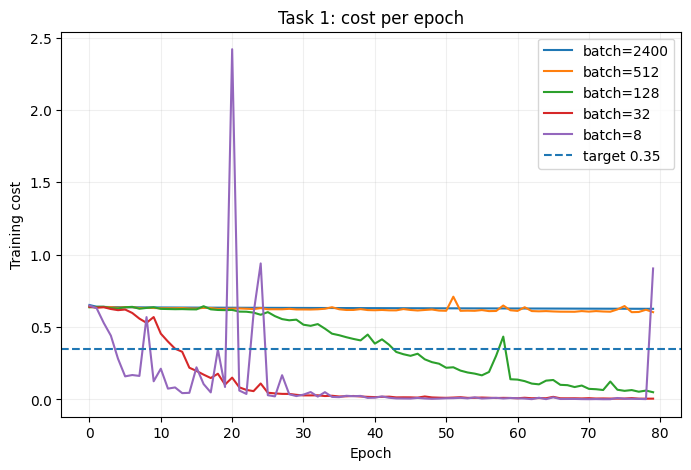

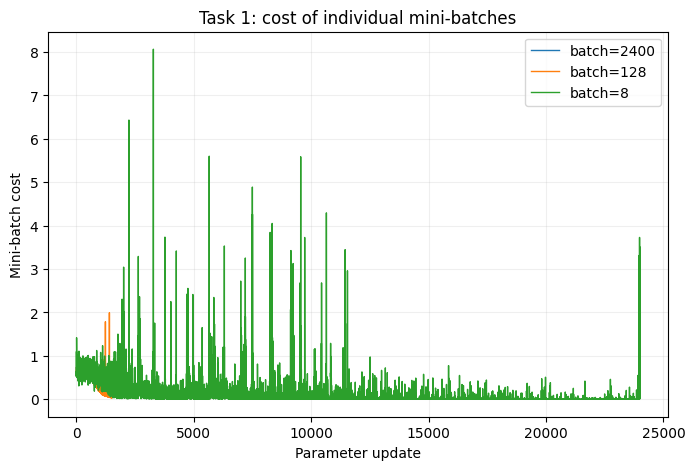

Batch sizes that never reach cost < 0.35: [2400, 512]

Batch 32 vs 8
batch=32: target_epoch=14, time=1.706s, final_cost=0.005336, test_acc=99.83%
batch=8: target_epoch=5, time=8.224s, final_cost=0.905009, test_acc=75.17%

Observation:
- Smaller batches perform many more parameter updates per epoch, so they can reach the target in fewer epochs.
- Very small batches make the mini-batch cost much noisier.
- Fewer epochs does not necessarily mean less wall-clock time because tiny batches reduce vectorization efficiency.


In [6]:

# Task 1 experiment
batch_sizes = [2400, 512, 128, 32, 8]
task1_results = {}
task1_rows = []

for bs in batch_sizes:
    r = train_model(
        optimizer="gd", lr=0.3, epochs=80, batch_size=bs,
        seed=1, record_batch_cost=(bs in [2400, 128, 8])
    )
    task1_results[bs] = r
    e = epochs_to_target(r["costs"])
    task1_rows.append([
        bs, r["updates"], e if e is not None else "Not reached",
        f'{r["costs"][-1]:.6f}',
        f'{100*r["train_acc"]:.2f}%',
        f'{100*r["test_acc"]:.2f}%',
        f'{r["wall_time"]:.3f}s'
    ])

print_table(
    ["Batch", "Updates", "Epoch<0.35", "Final cost", "Train acc", "Test acc", "Time"],
    task1_rows
)

# Plot 1: cost per epoch
plt.figure(figsize=(8,5))
for bs in batch_sizes:
    plt.plot(task1_results[bs]["costs"], label=f"batch={bs}")
plt.axhline(0.35, linestyle="--", label="target 0.35")
plt.xlabel("Epoch")
plt.ylabel("Training cost")
plt.title("Task 1: cost per epoch")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Plot 2: every mini-batch cost
plt.figure(figsize=(8,5))
for bs in [2400, 128, 8]:
    bc = task1_results[bs]["batch_costs"]
    plt.plot(bc, label=f"batch={bs}", linewidth=1)
plt.xlabel("Parameter update")
plt.ylabel("Mini-batch cost")
plt.title("Task 1: cost of individual mini-batches")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

never = [bs for bs in batch_sizes if epochs_to_target(task1_results[bs]["costs"]) is None]
print("Batch sizes that never reach cost < 0.35:", never)

print("\nBatch 32 vs 8")
for bs in [32, 8]:
    r = task1_results[bs]
    print(
        f"batch={bs}: target_epoch={epochs_to_target(r['costs'])}, "
        f"time={r['wall_time']:.3f}s, final_cost={r['costs'][-1]:.6f}, "
        f"test_acc={100*r['test_acc']:.2f}%"
    )

print("\nObservation:")
print("- Smaller batches perform many more parameter updates per epoch, so they can reach the target in fewer epochs.")
print("- Very small batches make the mini-batch cost much noisier.")
print("- Fewer epochs does not necessarily mean less wall-clock time because tiny batches reduce vectorization efficiency.")



### Task 1 written answers
- **Shuffle before splitting:** otherwise neighboring/ordered examples may repeatedly appear together, giving biased mini-batches.
- **Vary the seed each epoch:** this changes batch composition every epoch, while `seed + epoch` keeps the experiment reproducible.
- **Why some large batches fail within 80 epochs:** they make far fewer **parameter updates**. Each epoch still sees the full dataset, but learning occurs only when an update is made.
- **Noise:** batch 2400 is smoothest; batch 128 is moderately noisy; batch 8 is much noisier.
- **32 vs 8:** use the printed table to compare target epoch, wall-clock time and final position. A sensible practical choice is usually the one giving the best speed/accuracy trade-off rather than simply the fewest epochs.


# Task 2 — Exponentially Weighted Averages and Bias Correction

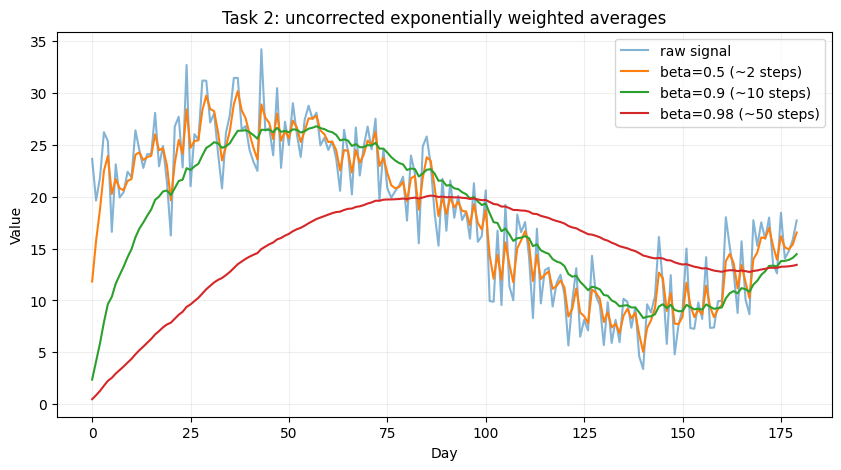

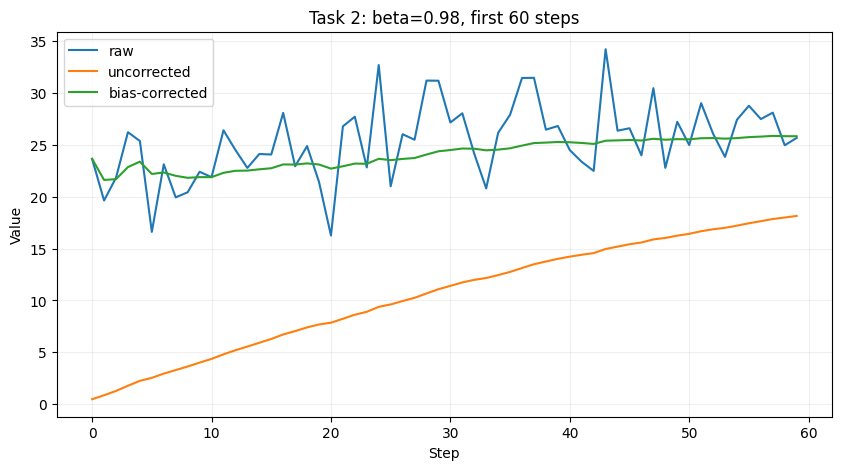

First five values:
t | raw       | uncorrected | corrected
--+-----------+-------------+----------
1 | 23.644968 | 0.472899    | 23.644968
2 | 19.629498 | 0.856031    | 21.616953
3 | 21.829526 | 1.275501    | 21.689247
4 | 26.216143 | 1.774314    | 22.855494
5 | 25.367917 | 2.246186    | 23.378484

By hand at t=1: v1=(1-beta)*x1 = 0.02*23.644968 = 0.472899
Computed uncorrected first value: 0.472899
Corrected first value: v1/(1-beta) = 23.644968 = x1

Interpretation:
beta=0.5 averages about 2 recent steps: responsive but noisy.
beta=0.9 averages about 10 recent steps: smoother, slower response.
beta=0.98 averages about 50 recent steps: very smooth, but responds slowly.
Bias correction matters early because initialization at zero pulls the average downward.
As t grows, beta**t -> 0, so 1-beta**t -> 1 and the correction becomes negligible.


In [7]:

np.random.seed(0)
days = np.arange(180)
signal = 18 + 10*np.sin(2*np.pi*days/180) + np.random.randn(180)*3.2

def ewa(x, beta, correct=False):
    v = 0.0
    out = []
    for i, xi in enumerate(x, start=1):
        v = beta*v + (1-beta)*xi
        if correct:
            out.append(v / (1 - beta**i))
        else:
            out.append(v)
    return np.array(out)

plt.figure(figsize=(10,5))
plt.plot(days, signal, alpha=0.55, label="raw signal")
for beta in [0.5, 0.9, 0.98]:
    plt.plot(days, ewa(signal, beta), label=f"beta={beta} (~{1/(1-beta):.0f} steps)")
plt.xlabel("Day")
plt.ylabel("Value")
plt.title("Task 2: uncorrected exponentially weighted averages")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

beta = 0.98
unc = ewa(signal, beta, correct=False)
cor = ewa(signal, beta, correct=True)

plt.figure(figsize=(10,5))
plt.plot(days[:60], signal[:60], label="raw")
plt.plot(days[:60], unc[:60], label="uncorrected")
plt.plot(days[:60], cor[:60], label="bias-corrected")
plt.xlabel("Step")
plt.ylabel("Value")
plt.title("Task 2: beta=0.98, first 60 steps")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("First five values:")
print_table(
    ["t", "raw", "uncorrected", "corrected"],
    [[i+1, f"{signal[i]:.6f}", f"{unc[i]:.6f}", f"{cor[i]:.6f}"] for i in range(5)]
)

manual_t1 = (1-beta)*signal[0]
print(f"\nBy hand at t=1: v1=(1-beta)*x1 = {1-beta:.2f}*{signal[0]:.6f} = {manual_t1:.6f}")
print(f"Computed uncorrected first value: {unc[0]:.6f}")
print(f"Corrected first value: v1/(1-beta) = {cor[0]:.6f} = x1")

print("\nInterpretation:")
print("beta=0.5 averages about 2 recent steps: responsive but noisy.")
print("beta=0.9 averages about 10 recent steps: smoother, slower response.")
print("beta=0.98 averages about 50 recent steps: very smooth, but responds slowly.")
print("Bias correction matters early because initialization at zero pulls the average downward.")
print("As t grows, beta**t -> 0, so 1-beta**t -> 1 and the correction becomes negligible.")


# Task 3 — Implementing Momentum, RMSProp and Adam

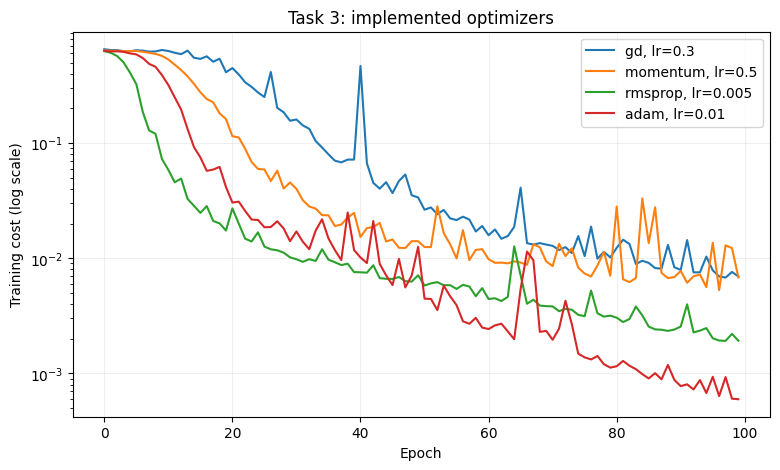

In [8]:

# Compare all four optimizers with representative learning rates.
task3_settings = {
    "gd": 0.3,
    "momentum": 0.5,
    "rmsprop": 0.005,
    "adam": 0.01
}
task3_results = {}

plt.figure(figsize=(9,5))
for opt, lr in task3_settings.items():
    r = train_model(opt, lr=lr, epochs=100, batch_size=64, seed=1)
    task3_results[opt] = r
    plt.plot(r["costs"], label=f"{opt}, lr={lr}")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training cost (log scale)")
plt.title("Task 3: implemented optimizers")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


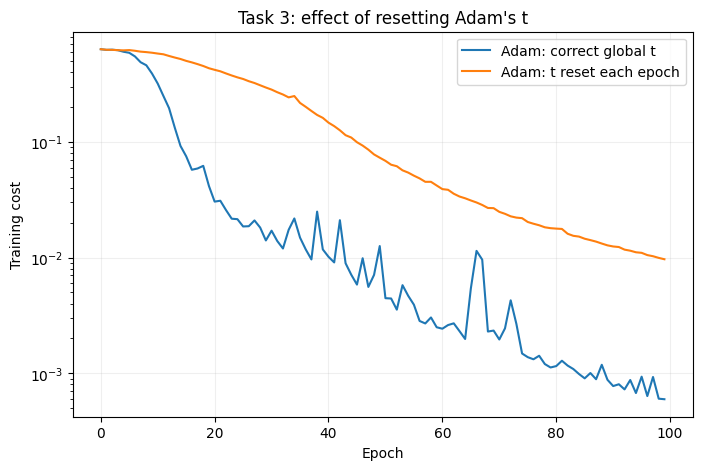

Final cost, correct Adam : 0.0005960858811156318
Final cost, reset-t Adam : 0.009666418530940465
Resetting t repeatedly re-applies strong early bias correction and changes/distorts the optimization path.


In [9]:

# Adam's t must count updates globally and must NOT reset each epoch.
adam_correct = train_model("adam", lr=0.01, epochs=100, batch_size=64, seed=1)
adam_wrong_t = train_model(
    "adam", lr=0.01, epochs=100, batch_size=64, seed=1,
    reset_adam_t_each_epoch=True
)

plt.figure(figsize=(8,5))
plt.plot(adam_correct["costs"], label="Adam: correct global t")
plt.plot(adam_wrong_t["costs"], label="Adam: t reset each epoch")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training cost")
plt.title("Task 3: effect of resetting Adam's t")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Final cost, correct Adam :", adam_correct["costs"][-1])
print("Final cost, reset-t Adam :", adam_wrong_t["costs"][-1])
print("Resetting t repeatedly re-applies strong early bias correction and changes/distorts the optimization path.")


Max curve difference: Adam(beta1=0) vs bias-corrected RMSProp = 0.0
Max curve difference: Adam(beta2=0) vs normalized momentum = 0.0


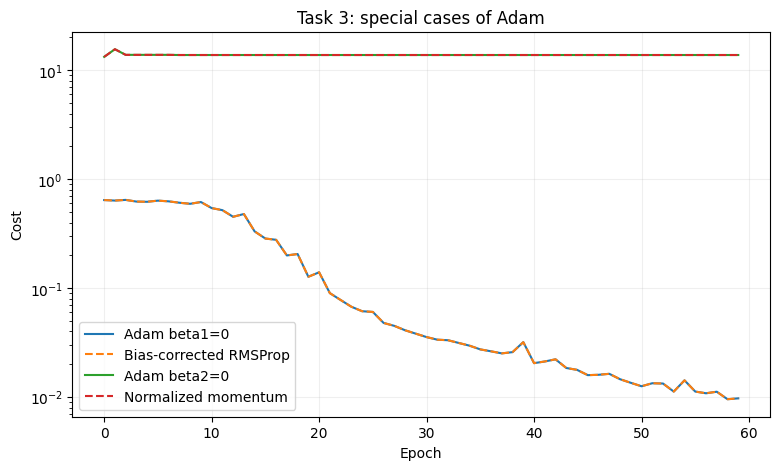


One-sentence explanations:
Momentum solves oscillation by averaging gradients, damping back-and-forth motion.
RMSProp solves unequal gradient scales by dividing each parameter update by a running RMS of its gradients.

Technical note:
The manual's plain RMSProp formula does not bias-correct its second moment.
Therefore Adam with beta1=0 is exactly equal to RMSProp only when RMSProp uses the same second-moment bias correction.
With beta2=0, Adam does not become ordinary Momentum; it becomes bias-corrected momentum divided by |current gradient|.


In [10]:

# beta1 = 0:
# v_hat becomes the current gradient, so Adam becomes RMSProp-like with a BIAS-CORRECTED
# second moment. To verify exact equality, compare with RMSProp using the same second-moment correction.

adam_b1_zero = train_model(
    "adam", lr=0.005, epochs=60, batch_size=64, seed=1, beta1=0.0, beta2=0.999
)
rmsprop_corrected = train_model(
    "rmsprop", lr=0.005, epochs=60, batch_size=64, seed=1,
    beta2=0.999, rmsprop_bias_correction=True
)

# beta2 = 0:
# s_hat = g^2, so denominator is |g|+epsilon.
# This is normalized momentum, NOT ordinary momentum.
adam_b2_zero = train_model(
    "adam", lr=0.01, epochs=60, batch_size=64, seed=1, beta1=0.9, beta2=0.0
)
norm_momentum = train_model(
    "normalized_momentum", lr=0.01, epochs=60, batch_size=64, seed=1, beta1=0.9
)

print("Max curve difference: Adam(beta1=0) vs bias-corrected RMSProp =",
      np.max(np.abs(adam_b1_zero["costs"] - rmsprop_corrected["costs"])))
print("Max curve difference: Adam(beta2=0) vs normalized momentum =",
      np.max(np.abs(adam_b2_zero["costs"] - norm_momentum["costs"])))

plt.figure(figsize=(9,5))
plt.plot(adam_b1_zero["costs"], label="Adam beta1=0")
plt.plot(rmsprop_corrected["costs"], "--", label="Bias-corrected RMSProp")
plt.plot(adam_b2_zero["costs"], label="Adam beta2=0")
plt.plot(norm_momentum["costs"], "--", label="Normalized momentum")
plt.yscale("log")
plt.xlabel("Epoch"); plt.ylabel("Cost")
plt.title("Task 3: special cases of Adam")
plt.legend(); plt.grid(alpha=0.2)
plt.show()

print("\nOne-sentence explanations:")
print("Momentum solves oscillation by averaging gradients, damping back-and-forth motion.")
print("RMSProp solves unequal gradient scales by dividing each parameter update by a running RMS of its gradients.")
print("\nTechnical note:")
print("The manual's plain RMSProp formula does not bias-correct its second moment.")
print("Therefore Adam with beta1=0 is exactly equal to RMSProp only when RMSProp uses the same second-moment bias correction.")
print("With beta2=0, Adam does not become ordinary Momentum; it becomes bias-corrected momentum divided by |current gradient|.")


# Task 4 — Comparing Optimizers Fairly

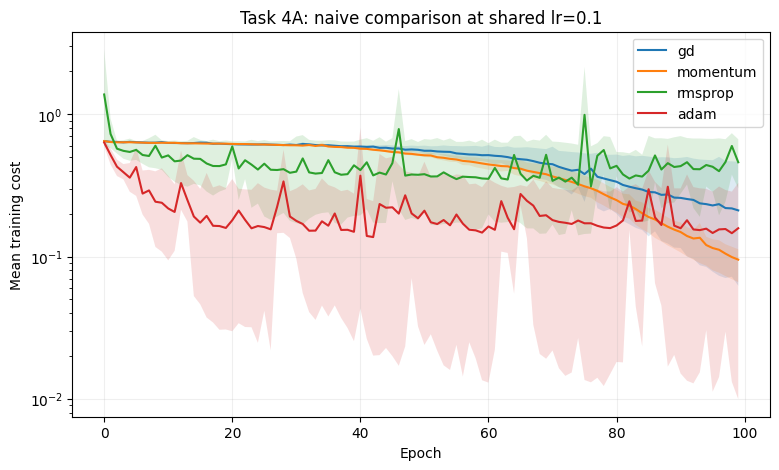

Optimizer | Mean test acc | Std   
----------+---------------+-------
gd        | 86.33%        | 15.49%
momentum  | 96.67%        | 1.53% 
rmsprop   | 69.44%        | 12.67%
adam      | 92.94%        | 5.89% 
Ranking by mean test accuracy: ['momentum', 'adam', 'gd', 'rmsprop']
Best at shared lr=0.1: momentum
Worst at shared lr=0.1: rmsprop


In [11]:

# Part A — naive comparison: same learning rate = 0.1, three seeds
optimizers = ["gd", "momentum", "rmsprop", "adam"]
seeds = [1, 2, 3]
naive = {}

plt.figure(figsize=(9,5))
for opt in optimizers:
    runs = [train_model(opt, lr=0.1, epochs=100, batch_size=64, seed=s) for s in seeds]
    naive[opt] = runs
    C = np.vstack([r["costs"] for r in runs])
    plt.plot(C.mean(axis=0), label=opt)
    plt.fill_between(np.arange(100), C.min(axis=0), C.max(axis=0), alpha=0.15)

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Mean training cost")
plt.title("Task 4A: naive comparison at shared lr=0.1")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

naive_rows = []
for opt in optimizers:
    test_accs = np.array([r["test_acc"] for r in naive[opt]])
    naive_rows.append([opt, f"{100*test_accs.mean():.2f}%", f"{100*test_accs.std():.2f}%"])

print_table(["Optimizer", "Mean test acc", "Std"], naive_rows)

ranked = sorted(
    optimizers,
    key=lambda o: np.mean([r["test_acc"] for r in naive[o]]),
    reverse=True
)
print("Ranking by mean test accuracy:", ranked)
print("Best at shared lr=0.1:", ranked[0])
print("Worst at shared lr=0.1:", ranked[-1])


Optimizer | LR     | Epoch<0.35  | Final cost
----------+--------+-------------+-----------
gd        | 0.03   | Not reached | 0.599419  
gd        | 0.1    | 77          | 0.107884  
gd        | 0.3    | 23          | 0.006951  
gd        | 0.5    | 17          | 0.005129  
gd        | 1.0    | 11          | 0.103517  
momentum  | 0.1    | 78          | 0.106676  
momentum  | 0.3    | 24          | 0.009386  
momentum  | 0.5    | 15          | 0.006805  
momentum  | 1.0    | 9           | 0.004040  
momentum  | 2.0    | 7           | 0.007962  
rmsprop   | 0.0005 | Not reached | 0.402268  
rmsprop   | 0.001  | 54          | 0.049744  
rmsprop   | 0.005  | 6           | 0.001920  
rmsprop   | 0.01   | 5           | 0.006158  
rmsprop   | 0.05   | 14          | 0.175076  
adam      | 0.001  | 79          | 0.184621  
adam      | 0.005  | 19          | 0.001783  
adam      | 0.01   | 11          | 0.000596  
adam      | 0.05   | 5           | 0.070548  
adam      | 0.1    | 4           |

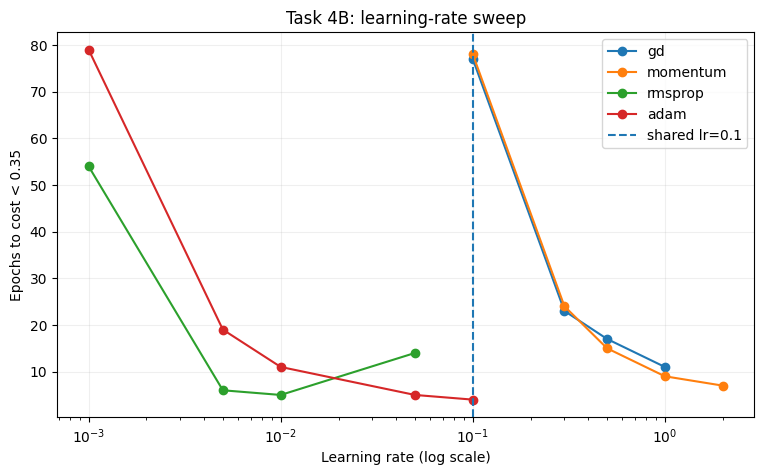

Chosen learning rates: {'gd': 0.5, 'momentum': 2.0, 'rmsprop': 0.01, 'adam': 0.01}

Why Part A is invalid:
Different optimizers have very different useful learning-rate ranges.
Using one shared learning rate can place one optimizer near its optimum while another is unstable or badly tuned.


In [12]:

# Part B — learning-rate sweep
lr_grid = {
    "gd":       [0.03, 0.1, 0.3, 0.5, 1.0],
    "momentum": [0.1, 0.3, 0.5, 1.0, 2.0],
    "rmsprop":  [0.0005, 0.001, 0.005, 0.01, 0.05],
    "adam":     [0.001, 0.005, 0.01, 0.05, 0.1]
}

sweep = {}
sweep_rows = []

for opt in optimizers:
    sweep[opt] = {}
    for lr in lr_grid[opt]:
        r = train_model(opt, lr=lr, epochs=100, batch_size=64, seed=1)
        e = epochs_to_target(r["costs"])
        sweep[opt][lr] = r
        sweep_rows.append([
            opt, lr, e if e is not None else "Not reached", f'{r["costs"][-1]:.6f}'
        ])

print_table(["Optimizer", "LR", "Epoch<0.35", "Final cost"], sweep_rows)

plt.figure(figsize=(9,5))
for opt in optimizers:
    xs = np.array(lr_grid[opt], dtype=float)
    ys = []
    for lr in xs:
        e = epochs_to_target(sweep[opt][float(lr)]["costs"])
        ys.append(np.nan if e is None else e)
    plt.plot(xs, ys, marker="o", label=opt)

plt.xscale("log")
plt.axvline(0.1, linestyle="--", label="shared lr=0.1")
plt.xlabel("Learning rate (log scale)")
plt.ylabel("Epochs to cost < 0.35")
plt.title("Task 4B: learning-rate sweep")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Selection rule:
# among final_cost < 0.02, choose the value reaching target soonest.
chosen_lr = {}
for opt in optimizers:
    eligible = []
    for lr in lr_grid[opt]:
        r = sweep[opt][lr]
        e = epochs_to_target(r["costs"])
        if r["costs"][-1] < 0.02 and e is not None:
            eligible.append((e, lr, r["costs"][-1]))
    if eligible:
        eligible.sort()
        chosen_lr[opt] = eligible[0][1]
    else:
        chosen_lr[opt] = None

print("Chosen learning rates:", chosen_lr)

print("\nWhy Part A is invalid:")
print("Different optimizers have very different useful learning-rate ranges.")
print("Using one shared learning rate can place one optimizer near its optimum while another is unstable or badly tuned.")


In [13]:

# Identify any optimizer whose fastest target-reaching LR is rejected by final-cost rule
for opt in optimizers:
    all_reached = []
    for lr in lr_grid[opt]:
        r = sweep[opt][lr]
        e = epochs_to_target(r["costs"])
        if e is not None:
            all_reached.append((e, lr, r["costs"][-1]))
    if all_reached:
        fastest = min(all_reached, key=lambda z: z[0])
        selected = chosen_lr[opt]
        if selected is not None and fastest[1] != selected:
            print(
                f"{opt}: fastest LR {fastest[1]} reaches target in {fastest[0]} epochs "
                f"but ends at cost {fastest[2]:.6f}; selected LR is {selected}."
            )


gd: fastest LR 1.0 reaches target in 11 epochs but ends at cost 0.103517; selected LR is 0.5.
adam: fastest LR 0.1 reaches target in 4 epochs but ends at cost 0.134863; selected LR is 0.01.


In [14]:

# Part C — fair comparison: each optimizer at its own chosen LR, three seeds
fair = {}
fair_rows = []

for opt in optimizers:
    lr = chosen_lr[opt]
    runs = [train_model(opt, lr=lr, epochs=100, batch_size=64, seed=s) for s in seeds]
    fair[opt] = runs

    target_epochs = [epochs_to_target(r["costs"]) for r in runs]
    final_costs = np.array([r["costs"][-1] for r in runs])
    test_accs = np.array([r["test_acc"] for r in runs])

    fair_rows.append([
        opt, lr,
        str(target_epochs),
        f"{final_costs.mean():.6f}",
        f"{100*test_accs.mean():.2f}%",
        f"{100*test_accs.std():.2f}%"
    ])

print_table(
    ["Optimizer", "Chosen LR", "Target epochs (3 seeds)", "Mean final cost", "Mean test acc", "Test acc std"],
    fair_rows
)

# Speed comparison
def mean_target_epochs(runs):
    vals = [epochs_to_target(r["costs"]) for r in runs]
    vals = [v for v in vals if v is not None]
    return np.mean(vals) if vals else np.inf

naive_speed = {o: mean_target_epochs(naive[o]) for o in optimizers}
fair_speed  = {o: mean_target_epochs(fair[o]) for o in optimizers}

best_naive = min(optimizers, key=lambda o: naive_speed[o])
best_fair  = min(optimizers, key=lambda o: fair_speed[o])

naive_factor = naive_speed["gd"] / naive_speed[best_naive]
fair_factor  = fair_speed["gd"] / fair_speed[best_fair]

print(f"\nNaive comparison: best={best_naive}; about {naive_factor:.2f}x faster than GD by mean epochs-to-target.")
print(f"Fair comparison : best={best_fair}; about {fair_factor:.2f}x faster than GD by mean epochs-to-target.")
print("The fair-comparison figure is the one that should be quoted in a report.")

stds = {
    o: np.std([r["test_acc"] for r in fair[o]]) for o in optimizers
}
least_consistent = max(stds, key=stds.get)
print("Least consistent across seeds:", least_consistent, "with test-accuracy std =", 100*stds[least_consistent], "%")
print("Consistency matters because a method that works only for lucky initialization/seeds is less reliable in practice.")


Optimizer | Chosen LR | Target epochs (3 seeds) | Mean final cost | Mean test acc | Test acc std
----------+-----------+-------------------------+-----------------+---------------+-------------
gd        | 0.5       | [17, 21, 21]            | 0.005440        | 99.83%        | 0.00%       
momentum  | 2.0       | [7, 7, 11]              | 0.150867        | 89.17%        | 14.97%      
rmsprop   | 0.01      | [5, 6, 8]               | 0.004865        | 99.83%        | 0.00%       
adam      | 0.01      | [11, 11, 12]            | 0.000610        | 99.94%        | 0.08%       

Naive comparison: best=adam; about 10.50x faster than GD by mean epochs-to-target.
Fair comparison : best=rmsprop; about 3.11x faster than GD by mean epochs-to-target.
The fair-comparison figure is the one that should be quoted in a report.
Least consistent across seeds: momentum with test-accuracy std = 14.967248194592031 %
Consistency matters because a method that works only for lucky initialization/seeds is les

# Task 5 — Learning-Rate Schedules

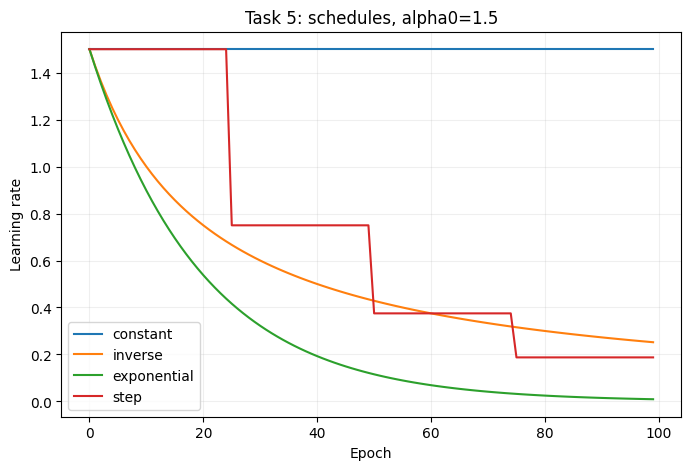

In [15]:

# The manual gives the inverse-decay formula but does not specify the decay constant.
# We use decay=0.05 and state this assumption explicitly.
INVERSE_DECAY = 0.05

def constant_schedule(alpha0, epoch):
    return alpha0

def inverse_schedule(alpha0, epoch):
    return alpha0 / (1 + INVERSE_DECAY*epoch)

def exponential_schedule(alpha0, epoch):
    return alpha0 * (0.95**epoch)

def step_schedule(alpha0, epoch):
    return alpha0 * (0.5**(epoch//25))

schedules = {
    "constant": constant_schedule,
    "inverse": inverse_schedule,
    "exponential": exponential_schedule,
    "step": step_schedule
}

epochs = np.arange(100)
plt.figure(figsize=(8,5))
for name, fn in schedules.items():
    plt.plot(epochs, [fn(1.5, e) for e in epochs], label=name)
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.title("Task 5: schedules, alpha0=1.5")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


Initial learning rate = 1.5
Schedule    | Epoch<0.35 | Final cost | Train acc | Test acc | Final LR   | Std(last20 cost)
------------+------------+------------+-----------+----------+------------+-----------------
constant    | 7          | 0.015096   | 99.25%    | 98.83%   | 1.50000000 | 0.00715362      
inverse     | 8          | 0.005384   | 99.79%    | 99.83%   | 0.25210084 | 0.00029639      
exponential | 8          | 0.012262   | 99.54%    | 99.67%   | 0.00934820 | 0.00005651      
step        | 7          | 0.009372   | 99.54%    | 99.67%   | 0.18750000 | 0.00032329      


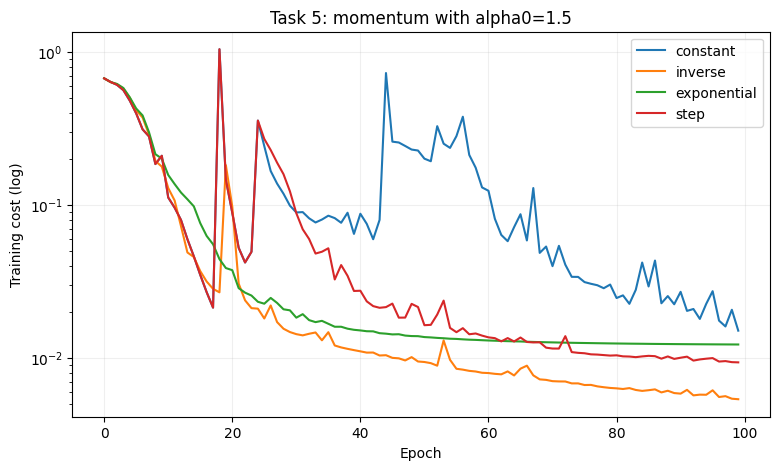

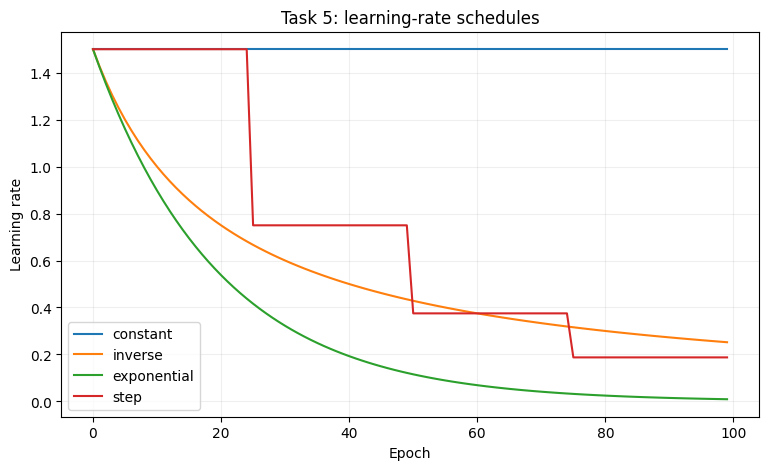


Explanation:
The constant high learning rate can reach the target quickly but keeps taking large noisy steps near the minimum.
A decaying rate reduces those late oscillations, so its last-20-epoch cost standard deviation is usually smaller and its final cost is better.


In [16]:

def run_schedule_experiment(alpha0):
    out = {}
    rows = []

    for name, sched in schedules.items():
        r = train_model(
            "momentum", lr=alpha0, epochs=100, batch_size=64,
            seed=1, schedule=sched
        )
        out[name] = r
        last20_std = np.std(r["costs"][-20:])
        rows.append([
            name,
            epochs_to_target(r["costs"]) if epochs_to_target(r["costs"]) is not None else "Not reached",
            f'{r["costs"][-1]:.6f}',
            f'{100*r["train_acc"]:.2f}%',
            f'{100*r["test_acc"]:.2f}%',
            f'{r["lr_history"][-1]:.8f}',
            f'{last20_std:.8f}'
        ])
    return out, rows

task5_15, rows15 = run_schedule_experiment(1.5)
print("Initial learning rate = 1.5")
print_table(
    ["Schedule", "Epoch<0.35", "Final cost", "Train acc", "Test acc", "Final LR", "Std(last20 cost)"],
    rows15
)

plt.figure(figsize=(9,5))
for name, r in task5_15.items():
    plt.plot(r["costs"], label=name)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training cost (log)")
plt.title("Task 5: momentum with alpha0=1.5")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(9,5))
for name, r in task5_15.items():
    plt.plot(r["lr_history"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.title("Task 5: learning-rate schedules")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("\nExplanation:")
print("The constant high learning rate can reach the target quickly but keeps taking large noisy steps near the minimum.")
print("A decaying rate reduces those late oscillations, so its last-20-epoch cost standard deviation is usually smaller and its final cost is better.")


In [17]:

# Verify the condition for decay: repeat with alpha0=0.5
task5_05, rows05 = run_schedule_experiment(0.5)
print("Initial learning rate = 0.5")
print_table(
    ["Schedule", "Epoch<0.35", "Final cost", "Train acc", "Test acc", "Final LR", "Std(last20 cost)"],
    rows05
)

print("\nGeneral condition:")
print("Learning-rate decay helps when the initial rate is useful for fast early movement but is too large for precise late convergence.")
print("If the initial rate is already small enough to settle cleanly, decay may give little benefit and can even slow progress.")


Initial learning rate = 0.5
Schedule    | Epoch<0.35 | Final cost | Train acc | Test acc | Final LR   | Std(last20 cost)
------------+------------+------------+-----------+----------+------------+-----------------
constant    | 15         | 0.006805   | 99.71%    | 99.67%   | 0.50000000 | 0.00813692      
inverse     | 21         | 0.016187   | 99.42%    | 99.50%   | 0.08403361 | 0.00124471      
exponential | 24         | 0.095596   | 97.29%    | 95.67%   | 0.00311607 | 0.00112990      
step        | 15         | 0.012824   | 99.50%    | 99.67%   | 0.06250000 | 0.00029645      

General condition:
Learning-rate decay helps when the initial rate is useful for fast early movement but is too large for precise late convergence.
If the initial rate is already small enough to settle cleanly, decay may give little benefit and can even slow progress.


# Task 6 — Trajectories on a Ravine and a Saddle

In [18]:

# Ravine
A, B = 0.01, 5.0
f = lambda w: A*w[0]**2 + B*w[1]**2
grad_f = lambda w: np.array([2*A*w[0], 2*B*w[1]])

curvature_w1 = 2*A
curvature_w2 = 2*B
condition_number = curvature_w2 / curvature_w1
gd_limit = 2 / curvature_w2

print("Curvature along w1 =", curvature_w1)
print("Curvature along w2 =", curvature_w2)
print("Condition number =", condition_number)
print("GD convergence condition in steep direction: |1 - alpha*10| < 1")
print("Therefore 0 < alpha < 0.2.  alpha=0.2 is the non-convergent boundary.")


Curvature along w1 = 0.02
Curvature along w2 = 10.0
Condition number = 500.0
GD convergence condition in steep direction: |1 - alpha*10| < 1
Therefore 0 < alpha < 0.2.  alpha=0.2 is the non-convergent boundary.


In [19]:

def optimize_surface(grad_fn, value_fn, w0, optimizer, lr, steps,
                     beta1=0.9, beta2=0.999, epsilon=1e-8, divergence_limit=1e20):
    w = np.array(w0, dtype=float)
    v = np.zeros_like(w)
    s = np.zeros_like(w)
    traj = [w.copy()]
    vals = [value_fn(w)]
    diverged_step = None

    for t in range(1, steps+1):
        g = grad_fn(w)

        if optimizer == "gd":
            update = g
        elif optimizer == "momentum":
            v = beta1*v + (1-beta1)*g
            update = v
        elif optimizer == "rmsprop":
            s = beta2*s + (1-beta2)*g*g
            update = g / (np.sqrt(s) + epsilon)
        elif optimizer == "adam":
            v = beta1*v + (1-beta1)*g
            s = beta2*s + (1-beta2)*g*g
            vhat = v/(1-beta1**t)
            shat = s/(1-beta2**t)
            update = vhat/(np.sqrt(shat) + epsilon)
        else:
            raise ValueError("unknown optimizer")

        w = w - lr*update
        traj.append(w.copy())
        val = value_fn(w)
        vals.append(val)

        if (not np.isfinite(val)) or abs(val) > divergence_limit or np.max(np.abs(w)) > divergence_limit:
            diverged_step = t
            break

    return np.array(traj), np.array(vals), diverged_step

# Requested GD learning rates
gd_lrs = [0.05, 0.10, 0.18, 0.20, 0.21, 0.25]
rows = []
for lr in gd_lrs:
    tr, vals, div = optimize_surface(grad_f, f, [-9,2], "gd", lr, 150)
    if div is None:
        rows.append([lr, f"{vals[-1]:.12g}", "No"])
    else:
        rows.append([lr, f"diverged at step {div}", "Yes"])

print_table(["GD LR", "f after 150 steps / divergence", "Diverged?"], rows)
print("\nWhy tuning cannot fully solve the ravine:")
print("The steep direction forces alpha below 0.2, while that same small alpha makes movement in the shallow w1 direction extremely slow.")


GD LR | f after 150 steps / divergence | Diverged?
------+--------------------------------+----------
0.05  | 0.599972696046                 | No       
0.1   | 0.444270426831                 | No       
0.18  | 0.274536870155                 | No       
0.2   | 20.2433809298                  | No       
0.21  | 5.23402199238e+13              | No       
0.25  | diverged at step 54            | Yes      

Why tuning cannot fully solve the ravine:
The steep direction forces alpha below 0.2, while that same small alpha makes movement in the shallow w1 direction extremely slow.


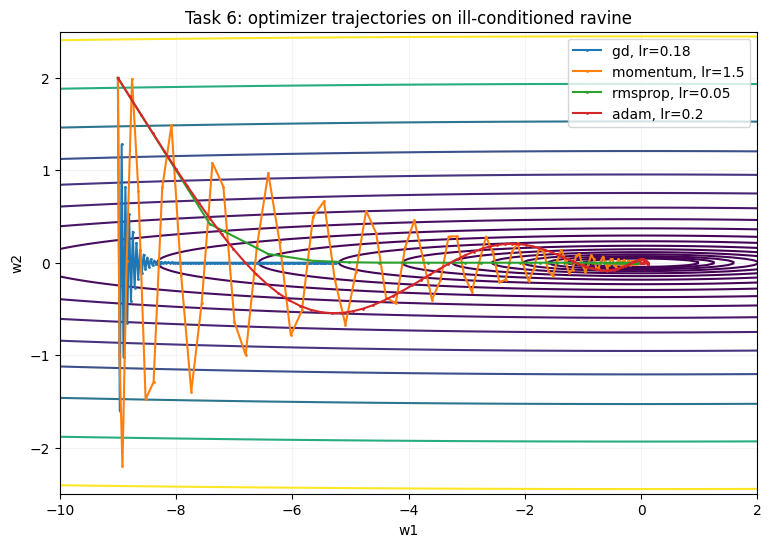

Optimizer | LR   | Final f          
----------+------+------------------
gd        | 0.18 | 0.274536870155   
momentum  | 1.5  | 4.15284371139e-06
rmsprop   | 0.05 | 4.76635333394e-13
adam      | 0.2  | 8.19447817909e-07

Trajectory descriptions:
GD zig-zags or must use a small stable step in the steep direction, so it crawls along the shallow direction.
Momentum averages alternating steep-direction gradients, reducing zig-zagging and accelerating movement along the ravine.


In [20]:

# Suitable learning rates chosen empirically for visualization of each optimizer.
surface_lr = {
    "gd": 0.18,
    "momentum": 1.5,
    "rmsprop": 0.05,
    "adam": 0.2
}

surface_runs = {}
for opt, lr in surface_lr.items():
    surface_runs[opt] = optimize_surface(grad_f, f, [-9,2], opt, lr, 150)

# Contours
x = np.linspace(-10, 2, 300)
y = np.linspace(-2.5, 2.5, 300)
XX, YY = np.meshgrid(x, y)
ZZ = A*XX**2 + B*YY**2

plt.figure(figsize=(9,6))
levels = np.geomspace(0.01, 30, 18)
plt.contour(XX, YY, ZZ, levels=levels)
for opt, (traj, vals, div) in surface_runs.items():
    plt.plot(traj[:,0], traj[:,1], marker=".", markersize=2,
             label=f"{opt}, lr={surface_lr[opt]}")
plt.xlabel("w1")
plt.ylabel("w2")
plt.title("Task 6: optimizer trajectories on ill-conditioned ravine")
plt.legend()
plt.grid(alpha=0.15)
plt.show()

rows = []
for opt, (traj, vals, div) in surface_runs.items():
    rows.append([opt, surface_lr[opt], f"{vals[-1]:.12g}"])
print_table(["Optimizer", "LR", "Final f"], rows)

print("\nTrajectory descriptions:")
print("GD zig-zags or must use a small stable step in the steep direction, so it crawls along the shallow direction.")
print("Momentum averages alternating steep-direction gradients, reducing zig-zagging and accelerating movement along the ravine.")


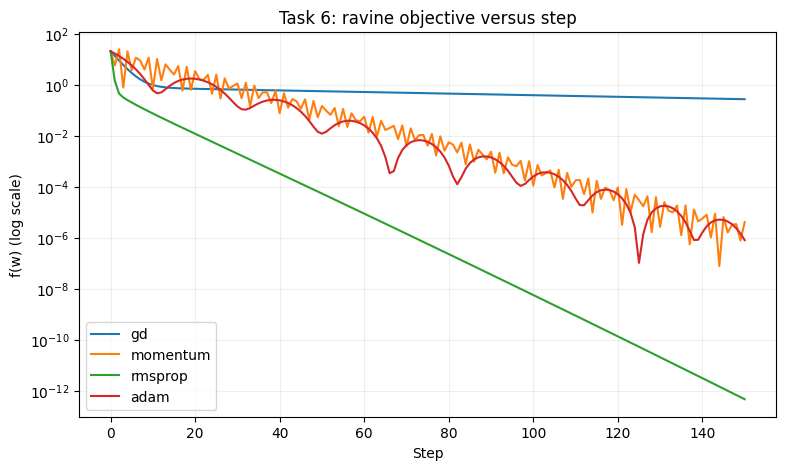

In [21]:

plt.figure(figsize=(9,5))
for opt, (traj, vals, div) in surface_runs.items():
    plt.plot(np.arange(len(vals)), vals, label=opt)
plt.yscale("log")
plt.xlabel("Step")
plt.ylabel("f(w) (log scale)")
plt.title("Task 6: ravine objective versus step")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


Optimizer | LR   | First step |w2| > 0.1
----------+------+----------------------
gd        | 0.18 | 15                   
momentum  | 1.5  | 10                   
rmsprop   | 0.05 | 1                    
adam      | 0.2  | 1                    


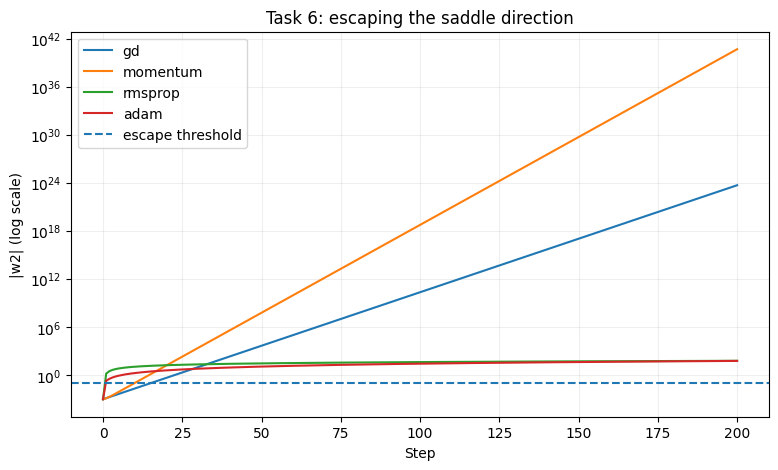


Explanation:
Near the saddle, the escape-direction gradient is initially tiny.
RMSProp and Adam divide by an adaptive gradient scale, so a small raw gradient can still produce a meaningful step.
That is why the adaptive methods can cross the escape threshold much earlier in this experiment.


In [22]:

# Saddle: f = w1^2 - w2^2
f_saddle = lambda w: w[0]**2 - w[1]**2
grad_saddle = lambda w: np.array([2*w[0], -2*w[1]])

saddle_rows = []
saddle_runs = {}

for opt, lr in surface_lr.items():
    traj, vals, div = optimize_surface(
        grad_saddle, f_saddle, [-1.4, 0.001], opt, lr, 200,
        divergence_limit=1e100
    )
    saddle_runs[opt] = (traj, vals)
    crossed = np.where(np.abs(traj[:,1]) > 0.1)[0]
    escape_step = int(crossed[0]) if len(crossed) else "Not reached"
    saddle_rows.append([opt, lr, escape_step])

print_table(["Optimizer", "LR", "First step |w2| > 0.1"], saddle_rows)

plt.figure(figsize=(9,5))
for opt, (traj, vals) in saddle_runs.items():
    plt.plot(np.abs(traj[:,1]), label=opt)
plt.axhline(0.1, linestyle="--", label="escape threshold")
plt.yscale("log")
plt.xlabel("Step")
plt.ylabel("|w2| (log scale)")
plt.title("Task 6: escaping the saddle direction")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("\nExplanation:")
print("Near the saddle, the escape-direction gradient is initially tiny.")
print("RMSProp and Adam divide by an adaptive gradient scale, so a small raw gradient can still produce a meaningful step.")
print("That is why the adaptive methods can cross the escape threshold much earlier in this experiment.")



# Final concise conclusions / viva-ready points

1. **Mini-batches:** smaller batches give more parameter updates per epoch; very small batches are noisier.
2. **EWA:** larger β gives a smoother but slower-moving average.
3. **Bias correction:** fixes the early downward bias caused by initializing the running average at zero.
4. **Momentum:** reduces oscillation by averaging gradients.
5. **RMSProp:** adapts step sizes parameter-by-parameter using squared gradients.
6. **Adam:** combines momentum + RMSProp-style scaling + bias correction.
7. **Fair optimizer comparison:** each optimizer must first be tuned over its own learning-rate range.
8. **Learning-rate decay:** helps when the early learning rate is good for speed but too large for final settling.
9. **Ill-conditioned ravine:** GD cannot simultaneously satisfy the steep-direction stability constraint and move quickly in the shallow direction.
10. **Saddle:** adaptive scaling can accelerate movement in a direction whose raw gradient is initially tiny.

## Submission checklist
- Rename to `Lab05_<YourRollNo>.ipynb`
- Replace `YOUR_ROLL_NO`
- Run **Runtime → Run all** once in Google Colab
- Confirm all plots/tables appear
- Put notebook inside `DeepLearningLab_<YourRollNo>/Lab05/`
